# The NEOARM model: console values in, beam on the camera out

One model of the whole column, from the source to the SightX, made of TemGym components. It takes what PyJEM reads
from the console (every lens and deflector DAC value) and gives where the beam lands on the camera and how big it
is. JAX differentiates it, so the same model also answers the opposite question: which DAC values put the beam
where I want it.

The model is **two short functions** (section 2) and **one table of numbers** (section 1). The rest of the notebook
says where the numbers come from (section 3), shows the model (sections 4–5), tests it against the real NEOARM
(section 6) and says what frames from one camera cannot tell (section 7).

**Everything is non-dimensional.**

| Quantity | Unit | Why |
|---|---|---|
| every length along the column, and lens field lengths | **L**, the specimen-to-SightX distance (specimen at 0, camera at 1) | no frame contains L |
| lens excitation | the **rotation angle θ** it gives the image (radians) | θ = √(e / 8mV*) · μ₀ · NI exactly (Ampère), and the image rotation measures it: 0.080 ampere-turns per DAC unit for every lens |
| lens strength | **L / f = θ² · φ / w** | w = (∫B dz)² / ∫B² dz is the lens field's effective length (units of L): for any field shape a weak lens focuses as θ² / w. φ = exp(a·x + b·x²), x = (DAC − the lens's middle DAC) / 20000, is how the real lens departs from that (the iron saturating, the field changing shape) |
| a thick lens's body | length = body · θ | IL2 and IL3 need it to follow the console's table |
| deflectors | radians per DAC unit | |
| camera | pixels per L, binned pixels (binning 4: a 479-pixel frame) | the one number that ties the model to the camera |

So there is no voltage, no ampere-turns and no strength constant Gc in the numbers: they are all inside θ and w.
TemGym's `ElectromagneticLens` is given them by a two-line conversion in `column`.

| Part | In the model | Its numbers |
|---|---|---|
| CL1, CL3, CM, IL1, IL2, IL3, PL1 | a TemGym `ElectromagneticLens` each | position, θ per DAC, w, φ (a, b), body, centre off the axis (x, y) |
| Objective | two fixed thin lenses: its field before and after the specimen | focal length, position |
| Probe corrector | two fixed thin lenses that hand the beam on turned over | (fixed) |
| CLA1, CLA2, IS1, IS2, PLA | a TemGym `Deflector` each | position, and a 2 × 2 matrix: radians per DAC unit |
| Source | three rays: the beam's centre, its size, its spread of angles | position and tilt of the centre, size, spread |
| SightX | pixels per L, and where the frame's middle is | |

In [1]:
import csv
import io
import json
import zipfile
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

jax.config.update("jax_enable_x64", True)

from temgym_core.components import Deflector, ElectromagneticLens, Lens, Plane
from temgym_core.components.lenses import compute_Rc_from_voltage
from temgym_core.constants import effective_accelerating_potential
from temgym_core.plotting import legacy_beam_plot_params, plot_model
from temgym_core.ray import Ray
from temgym_core.run import position_and_angle_response, run_to_end

HERE = Path.cwd()                                   # examples/microscope_inversion
VOLTAGE = 200e3
RC = float(compute_Rc_from_voltage(VOLTAGE))        # radians of rotation per ampere-turn (TemGym)
V_STAR = float(effective_accelerating_potential(VOLTAGE))
LENSES = ("CL1", "CL3", "CM", "IL1", "IL2", "IL3", "PL1")
DEFLECTORS = ("CLA1", "CLA2", "IS1", "IS2", "PLA")
MIDDLE_DAC = (32768.0, 32768.0, 32768.0, 31593.0, 43363.0, 31047.0, 61029.5)   # φ is measured from here: the middle
                                                    # of the DAC values the console table gives each projection lens
DRAWING = json.loads((HERE.parent / "virtual_neoarm/neoarm_column_diagram.json").read_text())["z_m"]
L_DRAWING = DRAWING["Screen"]                       # specimen to SightX on JEOL's drawing (m): only to print mm
tables = json.loads((HERE / "recordings/2026-11-17/console_tables.json").read_text())
NEUTRAL = {name: jnp.full(2, 32768.0) for name in DEFLECTORS}


def console(row):
    """The lens DAC values of a console row, with the deflectors at neutral."""
    return {name: jnp.asarray(row[name], float) for name in LENSES} | NEUTRAL

## 1. The numbers

Every array about lenses is in the order CL1, CL3, CM, IL1, IL2, IL3, PL1; every array about deflectors in the
order CLA1, CLA2, IS1, IS2, PLA.

The projection lenses (IL1–PL1) and the objective are **member 0 of a family**: seven different columns that all
follow the real console's lens table (in focus at every MAG and DIFF row), from section 3. Member 0 fits best. The
other six are *other plausible NEOARMs*: the offline notebook uses them as microscopes we pretend not to know.

The condenser: CM's w is designed (a parallel beam at spot 4, alpha 0); CL1's and CL3's w are fitted to the five
real parallel-beam settings (section 6, where spot 2 is kept back and predicted to 107 DAC units).
Positions of the condenser, the deflectors and the source: JEOL's column drawing. Deflector strengths, source and
misalignments: guesses. None of this is trusted: `neoarm_predictor_offline.ipynb` fits it to frames.

In [2]:
family = json.loads((HERE / "results/neoarm_family.json").read_text())["members"]
best = family[0]
p = dict(
    # lenses
    lens_z=[-0.7101, -0.5971, -0.1333, *best["lens_z"]],              # positions (L)
    theta_per_dac=RC * 0.080 * np.array([1, 1, 1, -1, -1, -1, 1.0]),  # image rotation per DAC unit (rad), with its sense
    lens_w=[0.0338, 0.0526, 0.14563, *best["lens_w"]],                # field length w (L): L/f = θ² φ / w
    phi_a=[0.0, 0.0, 0.0, *best["phi_a"]],                            # φ = exp(a·x + b·x²), x = (DAC − MIDDLE_DAC) / 20000
    phi_b=[0.0, 0.0, 0.0, *best["phi_b"]],
    lens_body=[0.0, 0.0, 0.0, *best["lens_body"]],                    # body length per radian of θ (L)
    lens_xy=np.zeros((7, 2)),                                         # each lens's centre, off the axis (L)
    # deflectors
    deflector_z=[-0.5786, -0.5623, 0.1226, 0.1839, best["lens_z"][3]],                      # PLA sits on PL1
    deflector_kick=[g * np.eye(2) for g in (3e-7, 3e-7, 1e-6, 3e-6, 3e-5)],                 # radians per DAC unit
    # fixed lenses
    corrector=[-0.5507, -0.2058],                                     # the corrector's top and bottom
    objective_f=best["objective_f"], objective_z=best["objective_z"],
    # source
    source_z=-0.9420, source=np.zeros(4),                             # the beam's centre there: x, y, tilt x, tilt y
    source_size=2e-8, source_angle=1e-4,                              # rms size (L) and rms spread of angles (rad)
    # camera
    camera_z=1.0, pixels_per_length=L_DRAWING / (4 * 62.6e-6),        # 1916 pixels across 12 cm, binned by 4
    camera_centre=np.zeros(2), camera_blur=1.0,                       # the frame's middle (pixels); the camera's blur
)
p = {key: jnp.asarray(value, float) for key, value in p.items()}
print(f"{'':5s}{'position':>10s}{'in mm':>8s}")
for name, z in zip(LENSES + DEFLECTORS, np.r_[p["lens_z"], p["deflector_z"]]):
    print(f"{name:5s}{z:10.4f}{z * L_DRAWING * 1e3:8.0f}")

       position   in mm
CL1     -0.7101    -510
CL3     -0.5971    -429
CM      -0.1333     -96
IL1      0.2452     176
IL2      0.3417     246
IL3      0.4364     314
PL1      0.5112     367
CLA1    -0.5786    -416
CLA2    -0.5623    -404
IS1      0.1226      88
IS2      0.1839     132
PLA      0.5112     367


## 2. The model

`column` builds the microscope for one set of console values: a plain list of TemGym components, top to bottom.
`beam_on_camera` sends three rays down it. The first is the beam's centre. The second starts one beam-size to the
side, the third one angle-spread tilted: how far they end from the first gives the beam's size on the camera.

The only conversion: TemGym's `ElectromagneticLens` takes ampere-turns (`turns × current`), a strength constant
`Gc` (1/f = Gc · NI² / V*) and a body `Tc` per ampere-turn. With NI = θ / RC these are turns = θ per DAC / RC,
Gc = V* · RC² · φ / w and Tc = body · RC.

These are functions (not loose code) for one reason: JAX differentiates functions, and maps them over thousands of
frames at once.

In [3]:
def column(p, dac):
    """The NEOARM as TemGym components, from below the source to the camera, for the console's values `dac`."""
    lens = {}
    for i, name in enumerate(LENSES):
        x = (dac[name] - MIDDLE_DAC[i]) / 20000
        phi = jnp.exp(p["phi_a"][i] * x + p["phi_b"][i] * x * x)
        lens[name] = ElectromagneticLens(
            z=p["lens_z"][i], turns=p["theta_per_dac"][i] / RC, current=dac[name],
            Gc=V_STAR * RC**2 * phi / p["lens_w"][i], Tc=p["lens_body"][i] * RC,
            x0=p["lens_xy"][i, 0], y0=p["lens_xy"][i, 1])
    deflector = {}
    for i, name in enumerate(DEFLECTORS):
        kick = p["deflector_kick"][i] @ (dac[name] - 32768.0)
        deflector[name] = Deflector(z=p["deflector_z"][i], def_x=kick[0], def_y=kick[1])
    top, bottom = p["corrector"]
    relay, f = (bottom - top) / 4, p["objective_f"]
    return [
        lens["CL1"], lens["CL3"], deflector["CLA1"], deflector["CLA2"],
        Lens(z=top + relay, focal_length=relay), Lens(z=bottom - relay, focal_length=relay),       # the corrector
        lens["CM"], Lens(z=-f, focal_length=f),                                                    # objective, before
        Plane(z=0.0),                                                                              # the specimen
        Lens(z=p["objective_z"], focal_length=f),                                                  # objective, after
        deflector["IS1"], deflector["IS2"], lens["IL1"], lens["IL2"], lens["IL3"], deflector["PLA"], lens["PL1"],
        Plane(z=p["camera_z"]),
    ]


def beam_on_camera(p, dac):
    """Where the beam lands (x, y: pixels from the frame's middle) and its size (rms along one axis, pixels)."""
    s = p["source"]
    rays = Ray(x=s[0] + jnp.array([0.0, 1.0, 0.0]) * p["source_size"], y=s[1] + jnp.zeros(3),
               dx=s[2] + jnp.array([0.0, 0.0, 1.0]) * p["source_angle"], dy=s[3] + jnp.zeros(3),
               z=p["source_z"] + jnp.zeros(3), pathlength=jnp.zeros(3), voltage=jnp.full(3, VOLTAGE))
    out = run_to_end(rays, column(p, dac))
    xy = jnp.stack([out.x, out.y], axis=1) * p["pixels_per_length"]
    size = jnp.sqrt(jnp.sum((xy[1:] - xy[0]) ** 2) + p["camera_blur"] ** 2)
    return jnp.r_[xy[0] + p["camera_centre"], size]


COMPONENT_NAMES = ["CL1", "CL3", "CLA1", "CLA2", "corrector", "", "CM", "objective", "specimen", "",
                   "IS1", "IS2", "IL1", "IL2", "IL3", "PLA", "PL1", "SightX"]
SPECIMEN = COMPONENT_NAMES.index("specimen")


def projection(p, dac):
    """From the specimen to the SightX: A (per unit shift) and B (L per radian of tilt), complex x + iy."""
    return position_and_angle_response(column(p, dac)[SPECIMEN + 1:], voltage=VOLTAGE)

## 3. Where the projection numbers come from: the console's lens table

The console's table says, row by row, with no absolute length:
* **MAG rows:** the specimen is in focus on the SightX, and the magnification is s × the label (one unknown s for
  all rows: the labels refer to JEOL's own plane, not the SightX);
* **DIFF rows:** the back focal plane is in focus (a specimen shift does not move the pattern), and the camera
  length is c × the label (one unknown c, which also holds L).

The fit's free numbers: the objective's focal length and magnification, the five gaps from the specimen to the
SightX (they add up to 1, so lenses never swap order), each projection lens's w, body, a and b, and s, c. Loose pulls
keep it physical: each gap near the drawing's (to 30 %), the labels right to 20 % (s near 1, c × L near the
drawing's L), the objective's focal length about 2 mm, no lens body thicker than 4 cm, a and b near 0. Without them
the fit finds silly columns (a magnification 1 % of the label with a lens 1 L thick).

Plain thin lenses (no φ, no body) cannot follow MAG and DIFF together: IL1 runs at about 20,000 in DIFF and
27,000–43,000 in MAG. Tried and not good enough (2026-11-18): φ with only a (misfit 218 against 56, and labels
4.5 times off); lenses from Lenz's pole-piece field, strength fixed by θ (192–266, with gaps of up to 20 cm).

Levenberg–Marquardt in JAX from 1024 random starts at once on the GPU (a few minutes). `REFIT = False` shows the
saved family; `True` redoes it and saves the seven best different ends.

In [4]:
REFIT = False
PROJECTION = ("IL1", "IL2", "IL3", "PL1")
MAG_ROWS = [r for r in tables["rows"]["MAG"] if 8000 <= r["mag"][0] <= 500000 and r["mag"][2] != "X25k"]
DIFF_ROWS = [r for r in tables["rows"]["DIFF"] if r["mag"][1] == "mm" and r["OLf"] > 0 and 80 <= r["mag"][0] <= 2000]
MAG_LABEL = np.array([r["mag"][0] for r in MAG_ROWS], float)
DIFF_LABEL = np.array([r["mag"][0] / 1000 for r in DIFF_ROWS], float)                 # metres
DRAWING_GAPS = np.diff([0, *(DRAWING[name] for name in PROJECTION), L_DRAWING]) / L_DRAWING
THETA_MAX = np.abs(np.asarray(p["theta_per_dac"][3:])) * np.max([[r[n] for n in PROJECTION] for r in MAG_ROWS + DIFF_ROWS], 0)


def projection_numbers(u):
    """The fit's free numbers -> the model's projection numbers (and s, c)."""
    gaps = jax.nn.softmax(jnp.log(DRAWING_GAPS) + jnp.r_[u[2:6], 0.0])
    f = jnp.exp(u[0])
    numbers = dict(objective_f=f, objective_z=f * (1 + jnp.exp(-u[1])), lens_z=jnp.cumsum(gaps)[:4],
                   lens_w=jnp.exp(u[6:10]), lens_body=jnp.exp(u[10:14]), phi_a=u[16:20], phi_b=u[20:24])
    return numbers, jnp.exp(u[14]), jnp.exp(u[15])


def with_projection(p, numbers):
    """p with the projection lenses and the objective replaced."""
    q = dict(p, objective_f=numbers["objective_f"], objective_z=numbers["objective_z"])
    for key in ("lens_z", "lens_w", "lens_body", "phi_a", "phi_b"):
        q[key] = p[key].at[3:].set(numbers[key])
    return q


def misfits(u):
    """Every misfit, in units of its allowed error."""
    numbers, s, c = projection_numbers(u)
    q = with_projection(p, numbers)
    a, b = (jnp.abs(jnp.stack(v)) for v in zip(*[projection(q, console(r)) for r in MAG_ROWS]))
    mag = (jnp.log(a) - jnp.log(s * MAG_LABEL)) / 0.03
    mag_focus = (b / a) / (1e-6 / L_DRAWING)                        # in focus: within 1 µm at the specimen
    a, b = (jnp.abs(jnp.stack(v)) for v in zip(*[projection(q, console(r)) for r in DIFF_ROWS]))
    diff = (jnp.log(b) - jnp.log(c * DIFF_LABEL)) / 0.03
    diff_focus = a / 20.0
    gaps = jnp.log(jnp.diff(jnp.r_[0.0, numbers["lens_z"], 1.0]) / DRAWING_GAPS) / 0.3
    labels = jnp.stack([jnp.log(s), jnp.log(c * L_DRAWING)]) / 0.2
    objective = jnp.log(numbers["objective_f"] * L_DRAWING / 2e-3)[None] / np.log(1.5)
    thin = jax.nn.relu(numbers["lens_body"] * THETA_MAX - 0.06) / 0.005
    perfect = jnp.r_[numbers["phi_a"], numbers["phi_b"]] / 2.0
    return jnp.concatenate([mag, mag_focus, diff, diff_focus, gaps, labels, objective, thin, perfect])


def lm_step(state, _):
    """One Levenberg–Marquardt step: solve (JᵀJ + λ diag JᵀJ) δ = −Jᵀr; keep it if the misfit drops."""
    u, lam, cost = state
    r, J = misfits(u), jax.jacfwd(misfits)(u)
    H = J.T @ J
    step = jnp.linalg.solve(H + lam * jnp.diag(jnp.diag(H) + 1e-9), -J.T @ r)
    new = misfits(u + step) @ misfits(u + step)
    better = jnp.isfinite(new) & (new < cost)
    return (jnp.where(better, u + step, u), jnp.clip(jnp.where(better, lam / 3, lam * 5), 1e-12, 1e12),
            jnp.where(better, new, cost)), None


@jax.jit
@jax.vmap
def fit_console(u):
    (u, _, cost), _ = jax.lax.scan(lm_step, (u, 1e-2, misfits(u) @ misfits(u)), None, length=400)
    return u, cost


if REFIT:
    rng = np.random.default_rng(0)
    middle = np.array([np.median([r[n] for r in MAG_ROWS + DIFF_ROWS]) for n in PROJECTION])
    theta = np.abs(np.asarray(p["theta_per_dac"][3:])) * middle
    starts = jnp.array([np.r_[np.log(rng.uniform(1.5e-3, 3e-3) / L_DRAWING), np.log(rng.uniform(20, 80)),
                              rng.uniform(-0.2, 0.2, 4), np.log(theta**2 * rng.uniform([0.01] * 3 + [0.005], [0.2] * 3 + [0.1])),
                              np.log(rng.uniform(1e-6, 1e-4, 4) / RC), np.log(rng.uniform(0.7, 2.5)),
                              np.log(rng.uniform(0.7, 2.5) / L_DRAWING), rng.uniform(-0.3, 0.3, 8)] for _ in range(1024)])
    ends, costs = fit_console(starts)
    costs = np.where(np.isfinite(costs), np.asarray(costs), np.inf)
    members = []
    for k in np.argsort(costs):
        if len(members) < 7 and all(abs(costs[k] - m["misfit"]) > 0.5 for m in members):
            numbers, _, _ = projection_numbers(ends[k])
            members.append(dict(misfit=float(costs[k])) | {key: np.asarray(v).tolist() for key, v in numbers.items()})
    (HERE / "results/neoarm_family.json").write_text(json.dumps(dict(
        note="Seven projection columns that follow the console's lens table (neoarm_model.ipynb, section 3).",
        members=members), indent=1))
    family, best = members, members[0]
print("the family's misfits:", [round(m["misfit"], 1) for m in family])

the family's misfits: [56.0, 111.2, 117.5, 121.2, 129.0, 143.0, 143.8]


How member 0 follows the console: magnification / label (the same s at every row, ideally) and camera length / label
(the same c). The two factors differ (0.47 and 0.82 here, with the drawing's L): the labels refer to JEOL's own
plane, and the objective's focal length and L both enter. The rings and the grating separate them (section 7).

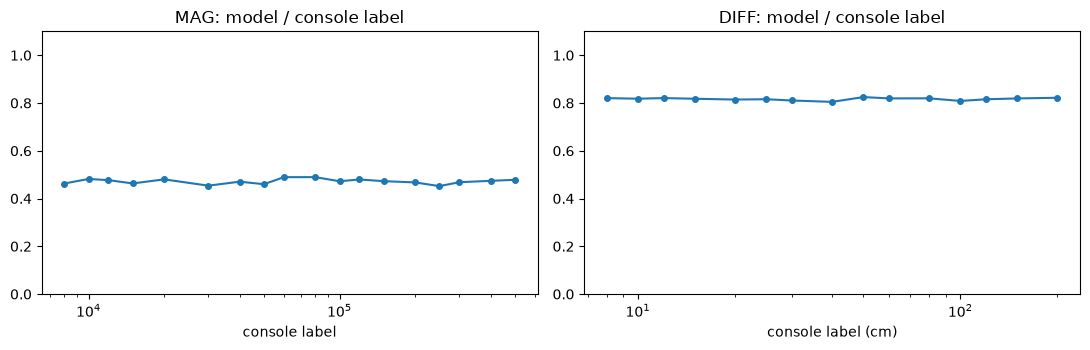

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, mode, rows, label in ((axes[0], "MAG", MAG_ROWS, MAG_LABEL), (axes[1], "DIFF", DIFF_ROWS, DIFF_LABEL)):
    ab = np.array([projection(p, console(r)) for r in rows])
    ratio = np.abs(ab[:, 0]) / label if mode == "MAG" else np.abs(ab[:, 1]) * L_DRAWING / label
    ax.semilogx(label if mode == "MAG" else label * 100, ratio, "o-", ms=4)
    ax.set(title=f"{mode}: model / console label", xlabel="console label" + ("" if mode == "MAG" else " (cm)"),
           ylim=(0, 1.1))
fig.tight_layout()

## 4. One console row

MAG 40k, as `record_console_tables.py` read it (spot 4, alpha 0), with the deflectors at neutral (32768). For each
lens: its strength L/f, its rotation θ, and its effective field length w / φ in mm (for a real pole piece, a few mm).

The console tables were read at **alpha 0** (CM 58624). The recordings of 2026-11-10 and the `calimages` were taken
with CM 26624, which is the console's alpha 1.

In [6]:
row = next(r for r in tables["rows"]["MAG"] if r["mag"][2] == "X40k")
dac = console(row)
components = column(p, dac)
print(f"MAG 40k{'':5s}{'position':>9s}{'L / f':>8s}{'θ':>9s}{'w/φ (mm)':>10s}")
for i, name in enumerate(LENSES):
    part = components[COMPONENT_NAMES.index(name)]
    x = (dac[name] - MIDDLE_DAC[i]) / 20000
    w = p["lens_w"][i] / jnp.exp(p["phi_a"][i] * x + p["phi_b"][i] * x * x)
    print(f"{name:12s}{float(part.z):9.3f}{1 / float(part.focal_length(VOLTAGE)):8.1f}"
          f"{np.degrees(float(part.rotation_angle(VOLTAGE))):8.1f}°{float(w) * L_DRAWING * 1e3:10.1f}")
print("\nbeam on the camera (x, y, size in pixels):", np.round(np.asarray(beam_on_camera(p, dac)), 2))

MAG 40k      position   L / f        θ  w/φ (mm)
CL1            -0.710    36.3    63.4°      24.3
CL3            -0.597    16.4    53.2°      37.8
CM             -0.133    21.9   102.4°     104.7
IL1             0.245    99.6   -73.0°      11.7
IL2             0.342    26.5   -43.4°      15.6
IL3             0.436    36.2   -62.1°      23.3
PL1             0.511   178.6   111.8°      15.3



beam on the camera (x, y, size in pixels): [  0.     0.   256.02]


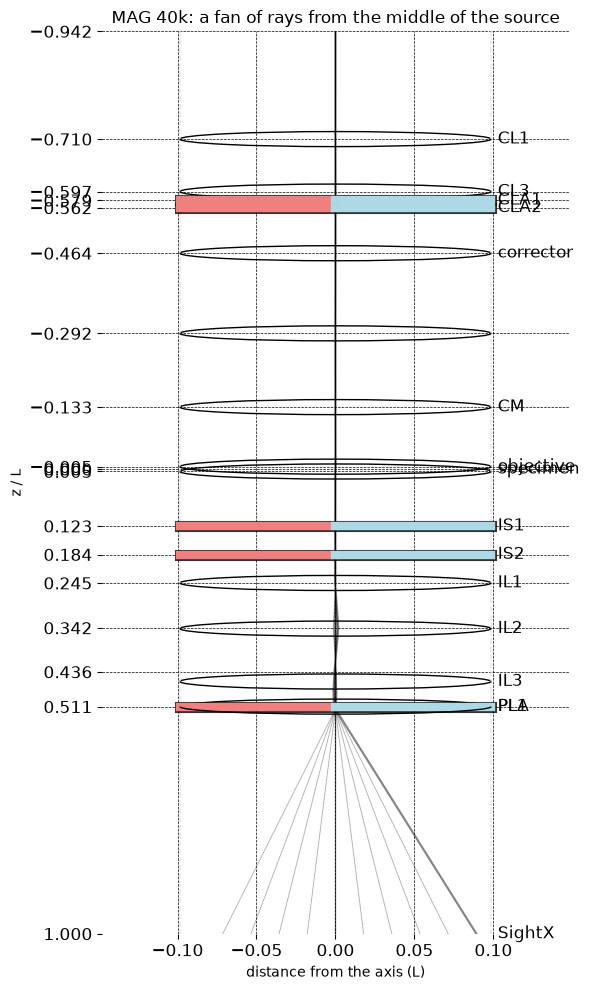

In [7]:
angles = np.linspace(-1, 1, 11) * float(p["source_angle"])
fan = Ray(x=np.zeros(11), y=np.zeros(11), dx=angles, dy=np.zeros(11), z=np.full(11, float(p["source_z"])),
          pathlength=np.zeros(11), voltage=np.full(11, VOLTAGE))
fig, ax = plt.subplots(figsize=(6, 10))
plot_model(components, rays=fan, ax=ax, plot_params=legacy_beam_plot_params(figsize=(5.0, 9.0)),
           ray_coordinate="x_rot", component_labels=COMPONENT_NAMES)
ax.set(title="MAG 40k: a fan of rays from the middle of the source", xlabel="distance from the axis (L)",
       ylabel="z / L")
fig.tight_layout()

## 5. What a change of one control does: gradients

`jax.jacfwd` gives, in one call, how far the beam moves and how much its size changes per DAC unit of **every**
control. These slopes are what makes the model usable for control: to move the beam somewhere, divide by them
(the last cells of the offline notebook do it on a microscope).

In [8]:
slopes = jax.jacfwd(beam_on_camera, argnums=1)(p, dac)
print(f"MAG 40k: per DAC unit{'x (px)':>12s}{'y (px)':>10s}{'size (px)':>11s}")
for name in LENSES:
    print(f"{name:21s}{float(slopes[name][0]):12.4f}{float(slopes[name][1]):10.4f}{float(slopes[name][2]):11.4f}")
for name in DEFLECTORS:
    for axis in (0, 1):
        print(f"{name + ' xy'[axis + 1]:21s}{float(slopes[name][0, axis]):12.4f}{float(slopes[name][1, axis]):10.4f}"
              f"{float(slopes[name][2, axis]):11.4f}")

MAG 40k: per DAC unit      x (px)    y (px)  size (px)
CL1                        0.0000    0.0000     0.0142
CL3                        0.0000    0.0000    -0.0291
CM                         0.0000    0.0000     0.0063
IL1                        0.0000    0.0000     0.0190
IL2                        0.0000    0.0000     0.0100
IL3                        0.0000    0.0000    -0.0181
PL1                        0.0000    0.0000    -0.0076
CLA1x                      0.0813    0.0584     0.0000
CLA1y                     -0.0584    0.0813     0.0000
CLA2x                      0.0571    0.0410     0.0000
CLA2y                     -0.0410    0.0571     0.0000
IS1x                      -0.0547    0.1270     0.0000
IS1y                      -0.1270   -0.0547     0.0000
IS2x                      -0.0735    0.1707     0.0000
IS2y                      -0.1707   -0.0735     0.0000
PLAx                      -0.0156    0.0391     0.0000
PLAy                      -0.0391   -0.0156     0.0000


**The beam's size against CL3**, at three magnifications. CL3 focuses the beam onto the specimen at one value (the
dip) and spreads it either side. The same beam is 60 times bigger on the camera at 500k than at 8k, so at high
magnification only a narrow range of CL3 keeps it on the camera: the recipe has to size the beam at every row.

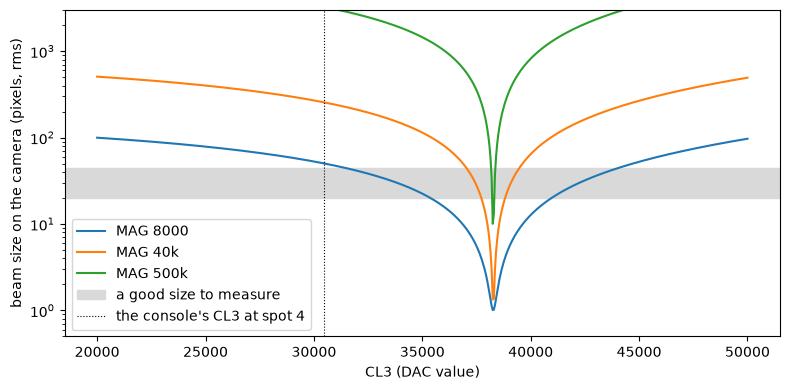

In [9]:
cl3 = jnp.linspace(20000, 50000, 601)
fig, ax = plt.subplots(figsize=(8, 4))
for label in ("X8000", "X40k", "X500k"):
    here = console(next(r for r in tables["rows"]["MAG"] if r["mag"][2] == label))
    size = jax.vmap(lambda value: beam_on_camera(p, here | dict(CL3=value))[2])(cl3)
    ax.semilogy(cl3, size, label=f"MAG {label[1:]}")
ax.axhspan(20, 45, color="0.85", label="a good size to measure")
ax.axvline(row["CL3"], color="k", lw=0.8, ls=":", label="the console's CL3 at spot 4")
ax.set(xlabel="CL3 (DAC value)", ylabel="beam size on the camera (pixels, rms)", ylim=(0.5, 3000))
ax.legend()
fig.tight_layout()

## 6. Against the real NEOARM

Three recordings from the real microscope, none of them used to make the numbers above.

**CLA1 at every magnification** (2026-11-10, `beam_per_magnification.zip`). At each MAG row from 8k to 500k the
beam was sized with CL3, and CLA1 moved along x and along y: a 2 × 2 matrix of pixels per CLA1 unit. The model does
not know CLA1's strength or direction, nor the camera's turn, so the matrix at **40k alone** fixes CLA1's 2 × 2
matrix; every other row is then a prediction. It tests the magnification steps and the image rotation together.
CM was 26624 in that session (alpha 1).

16 rows predicted from 40k: median error 2.6%, worst 9.2% (MAG 8,000); rotation within 0.6°


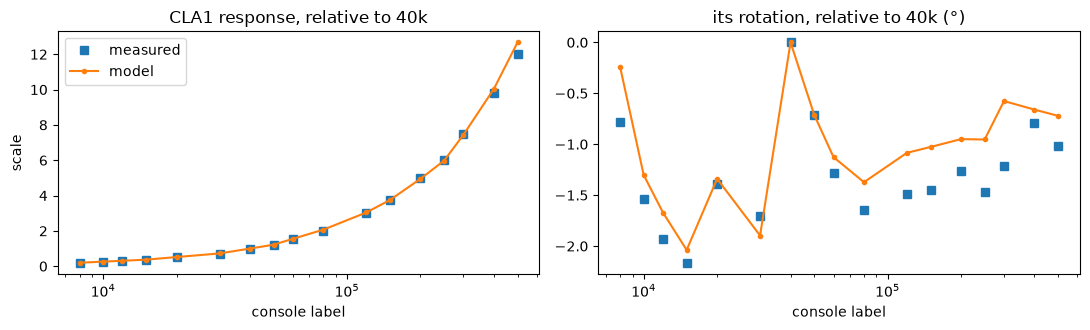

In [10]:
with zipfile.ZipFile(HERE / "recordings/2026-11-10/beam_per_magnification.zip") as archive:
    name = next(n for n in archive.namelist() if "beam_per_magnification_" in n and n.endswith("table.csv"))
    sweep = [r for r in csv.DictReader(io.StringIO(archive.read(name).decode())) if r["good"] == "True"]
mag_rows = {r["mag"][0]: r for r in MAG_ROWS}
sweep = [r for r in sweep if int(r["magnification"]) in mag_rows]
settings = [console(mag_rows[int(r["magnification"])]) | dict(CL1=jnp.asarray(float(r["CL1"])),
            CL3=jnp.asarray(float(r["CL3"])), CM=jnp.asarray(26624.0)) for r in sweep]
measured = np.array([json.loads(r["px_per_cla1_unit"]) for r in sweep])
labels = np.array([int(r["magnification"]) for r in sweep])


def cla1_per_radian(dac):
    """Pixels on the camera per radian of CLA1 kick (x and y): the optics after CLA1, without its unknown matrix."""
    unit = dict(p, deflector_kick=p["deflector_kick"].at[0].set(jnp.eye(2)))
    return jax.jacfwd(lambda d: beam_on_camera(unit, dac | dict(CLA1=d))[:2])(dac["CLA1"])


optics = np.array([cla1_per_radian(d) for d in settings])
at_40k = int(np.flatnonzero(labels == 40000)[0])
cla1_matrix = np.linalg.solve(optics[at_40k], measured[at_40k])          # radians per CLA1 unit, from 40k only
predicted = optics @ cla1_matrix
error = np.linalg.norm(predicted - measured, axis=(1, 2)) / np.linalg.norm(measured, axis=(1, 2))


def turn_and_scale(m):
    """Rotation (degrees) and scale of each matrix relative to 40k's."""
    r = m @ np.linalg.inv(m[at_40k])
    return np.degrees(np.arctan2(r[:, 1, 0] - r[:, 0, 1], r[:, 0, 0] + r[:, 1, 1])), np.sqrt(np.abs(np.linalg.det(r)))


(turn_m, scale_m), (turn_p, scale_p) = turn_and_scale(measured), turn_and_scale(predicted)
keep = labels != 40000
print(f"{keep.sum()} rows predicted from 40k: median error {np.median(error[keep]):.1%}, worst {error[keep].max():.1%}"
      f" (MAG {labels[keep][np.argmax(error[keep])]:,}); rotation within {np.abs(turn_p - turn_m)[keep].max():.1f}°")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].semilogx(labels, scale_m, "s", label="measured")
axes[0].semilogx(labels, scale_p, "o-", ms=3, label="model")
axes[0].set(title="CLA1 response, relative to 40k", xlabel="console label", ylabel="scale")
axes[0].legend()
axes[1].semilogx(labels, turn_m, "s", label="measured")
axes[1].semilogx(labels, turn_p, "o-", ms=3, label="model")
axes[1].set(title="its rotation, relative to 40k (°)", xlabel="console label")
fig.tight_layout()

**Projection lenses changed one at a time** (2026-11-10, `imaging-system-fitting-40k-40cm.zip`). At MAG 40k (CLA1
kicks) and DIFF 40 cm (CLA2 kicks), each of IL1, IL2, IL3 and PL1 was turned up and then down, and the kick measured
along x and y at each. The kick's response on the camera is A·(shift) + B·(tilt) at the specimen; the coil's shift
and tilt are unknown, so they are fitted to the start and the four "up" settings; the four "down" settings are
predicted. The score is the miss in the beam's kicked displacement (pixels), against two references: no change at
all, and the slopes measured from the "up" settings.

In [11]:
with zipfile.ZipFile(HERE / "recordings/2026-11-10/imaging-system-fitting-40k-40cm.zip") as archive:
    name = next(n for n in archive.namelist() if n.endswith("/table.csv"))
    frames = list(csv.DictReader(io.StringIO(archive.read(name).decode())))
home = console(mag_rows[40000])
blocks = []
for i in range(len(frames) - 4):
    rows = frames[i:i + 5]
    if ([r["role"] for r in rows] != ["not deflected", "deflected +", "deflected -", "deflected +", "deflected -"]
            or len({(r["mode"], r["setting"]) for r in rows}) != 1 or any(r["beam_usable"] != "True" for r in rows)):
        continue
    coil = rows[1]["deflector"]
    xy = np.array([complex(float(r["beam_x_px"]), float(r["beam_y_px"])) for r in rows])
    span = np.array([float(rows[1][coil + "_x"]) - float(rows[2][coil + "_x"]),
                     float(rows[3][coil + "_y"]) - float(rows[4][coil + "_y"])])
    blocks.append(dict(mode=rows[0]["mode"], name=rows[0]["setting"], kick=span / 2,
                       dac=np.array([float(rows[0][k]) for k in PROJECTION]), gain=(xy[[1, 3]] - xy[[2, 4]]) / span))

for mode in ("MAG 40k", "DIFF 40 cm"):
    group = [b for b in blocks if b["mode"] == mode]
    base = next(b for b in group if b["name"].endswith(" row"))
    train = [base] + [b for b in group if " +" in b["name"]]
    test = [b for b in group if " -" in b["name"]]
    ab = lambda bs: np.array([projection(p, home | dict(zip(PROJECTION, map(jnp.asarray, b["dac"])))) for b in bs])
    coil = np.linalg.lstsq(ab(train), np.array([b["gain"] for b in train]), rcond=None)[0]
    slope = np.linalg.solve(np.array([b["dac"] - base["dac"] for b in train[1:]]),
                            np.array([b["gain"] - base["gain"] for b in train[1:]]))
    truth, kick = np.array([b["gain"] for b in test]), np.array([b["kick"] for b in test])
    print(f"{mode}: {len(test)} settings predicted, the kick moved the beam {np.median(abs(truth * kick)):.0f} px")
    for label, guess in (("no change", base["gain"] + 0 * truth), ("the model", ab(test) @ coil),
                         ("measured slopes", base["gain"] + np.array([b["dac"] - base["dac"] for b in test]) @ slope)):
        print(f"   {label:16s} misses by {np.sqrt(np.mean(abs((guess - truth) * kick) ** 2)):5.1f} px rms")

MAG 40k: 4 settings predicted, the kick moved the beam 112 px


   no change        misses by  15.6 px rms
   the model        misses by  13.7 px rms
   measured slopes  misses by   2.1 px rms


DIFF 40 cm: 4 settings predicted, the kick moved the beam 98 px


   no change        misses by  10.1 px rms
   the model        misses by   4.4 px rms
   measured slopes  misses by   0.6 px rms


**The parallel beam at each spot** (`calimages.zip`). For spots 0–4 an operator set CL3 to make the beam parallel
at the specimen, with CM at 26624. In the model a beam from a point source is parallel when a ray leaving the
source tilted leaves the specimen untilted (after taking out the condenser's rotation). CL1's and CL3's w are
fitted to spots 0, 1, 3 and 4 (spot 2 kept back), starting from a grid; the fitted values are the ones in section 1.
The designed condenser this replaced (w 40 and 16 mm) put the parallel beam thousands of DAC units off, and had none
at spot 0.

In [12]:
with zipfile.ZipFile(HERE / "calimages.zip") as archive:
    spots = []
    for name in sorted(n for n in archive.namelist() if "parallel" in n and n.endswith(".npz")):
        with np.load(io.BytesIO(archive.read(name))) as frame:
            spots.append([int(frame[key]) for key in ("cl1", "cl3", "clm")])
spots = np.array(sorted(spots), float)                                   # CL1, CL3, CM; spot 0 first


def leaving_tilt(q, cl1, cl3, cm):
    """The tilt at the specimen of a ray that left the source at unit tilt (rotation taken out)."""
    ray = Ray(x=0.0, y=0.0, dx=1.0, dy=0.0, z=q["source_z"], pathlength=0.0, voltage=VOLTAGE)
    out = run_to_end(ray, column(q, home | dict(CL1=cl1, CL3=cl3, CM=cm))[:SPECIMEN + 1])
    turn = q["theta_per_dac"][:3] @ jnp.array([cl1, cl3, cm])
    return out.dx * jnp.cos(turn) + out.dy * jnp.sin(turn)


def parallel_cl3_squared(log_w, cl1, cm):
    """CL3² that makes the beam parallel: the tilt is a straight line in CL3² (a thin lens, L/f ∝ CL3²). Negative:
    no CL3 makes it parallel."""
    q = dict(p, lens_w=p["lens_w"].at[:2].multiply(jnp.exp(log_w)))
    t1, t2 = leaving_tilt(q, cl1, 20000.0, cm), leaving_tilt(q, cl1, 40000.0, cm)
    return 20000.0**2 - t1 * (40000.0**2 - 20000.0**2) / (t2 - t1)


all_spots = jax.jit(jax.vmap(parallel_cl3_squared, in_axes=(None, 0, 0)))
train = np.array([0, 1, 3, 4])
miss = jax.jit(lambda g: (all_spots(g, spots[train, 0], spots[train, 2]) - spots[train, 1] ** 2) / (2 * spots[train, 1]))
grid = jnp.stack(jnp.meshgrid(jnp.linspace(-1.5, 1.5, 31), jnp.linspace(-1.5, 1.5, 31)), -1).reshape(-1, 2)
cost = jnp.nan_to_num(jnp.sum(jax.vmap(miss)(grid) ** 2, axis=1), nan=jnp.inf)
g, lam = grid[jnp.argmin(cost)], 1e-2                                    # the best of a grid, then Levenberg–Marquardt
for _ in range(40):
    r, J = miss(g), jax.jacfwd(miss)(g)
    trial = g - jnp.linalg.solve(J.T @ J + lam * jnp.diag(jnp.diag(J.T @ J)), J.T @ r)
    g, lam = (trial, lam / 3) if jnp.sum(miss(trial) ** 2) < jnp.sum(r ** 2) else (g, lam * 5)
print("CL1's and CL3's w (mm): in the model", np.round(np.asarray(p["lens_w"][:2]) * L_DRAWING * 1e3, 1),
      " fitted", np.round(np.asarray(p["lens_w"][:2] * jnp.exp(g)) * L_DRAWING * 1e3, 1))
show = lambda sq: [f"{np.sqrt(v):.0f}" if v > 0 else "none" for v in np.asarray(sq)]
designed, fitted = show(all_spots(jnp.zeros(2), spots[:, 0], spots[:, 2])), show(all_spots(g, spots[:, 0], spots[:, 2]))
print(f"{'spot':>4s}{'CL1':>8s}{'operator CL3':>14s}{'the model':>10s}{'fitted':>9s}")
for i, (cl1, cl3, cm) in enumerate(spots):
    print(f"{i:4d}{cl1:8.0f}{cl3:14.0f}{designed[i]:>10s}{fitted[i]:>9s}", "  kept back" if i == 2 else "")

CL1's and CL3's w (mm): in the model [24.3 37.8]  fitted [24.3 37.8]


spot     CL1  operator CL3 the model   fitted
   0   26112         37805     37924    37897 
   1   28672         33600     33372    33353 
   2   31232         31214     31123    31107   kept back
   3   33792         29758     29784    29770 
   4   36320         28750     28910    28897 


## 7. What frames from one camera can and cannot tell

The camera only sees where the beam is, in pixels. Three changes to the numbers leave every frame exactly the same,
so no fit to SightX frames can find them. The model fixes each by a choice:

| Change that no frame can see | Fixed here by | What measures it later |
|---|---|---|
| Every length along the column longer (and every lens weaker) by one factor | the camera is at 1: lengths are in units of L | L itself: a known angle (gold rings) with the pixel size (the 12 cm screen), or the second camera |
| Every deflector stronger, with fewer pixels per length | `pixels_per_length` is not fitted | a known length at the specimen (the cross-grating) |
| The camera turned about the axis, with every deflector's matrix turned back | the camera is not turned | nothing needed: it only renames x and y |

One more is not exact but nearly so: **PL1 is at 64000 in almost every row**, so "PL1 stronger and the camera
further" looks the same in every frame. A fit to one camera therefore predicts the beam very well while its lens
*positions* stay loose (the offline notebook shows this). Positions need PL1 moved on purpose, or a second camera.

The rings and grating step has so far only been rehearsed on a simulated microscope (`fit_two_cameras.ipynb`,
`neoarm_forward.ipynb`): it has not been done on the real NEOARM yet.

The camera's handedness (is y up or down the frame) does matter: the wrong choice turns every lens the wrong way.
The offline notebook tests both and keeps the one that fits.

In [13]:
(HERE / "results/neoarm_model.json").write_text(json.dumps({key: np.asarray(value).tolist() for key, value in p.items()}, indent=1))
print("saved results/neoarm_model.json")

saved results/neoarm_model.json
